# 41 — Indicateurs de cruising par heure et par motif

Lit la collection de tables par leg (`legs_enriched` + une table par méthode : `relut_by_leg`, plus tard `spatial_by_leg`, `hybrid_by_leg`) et produit, pour chaque méthode disponible :

1. part de legs avec cruising, 2. durée, 3. distance du cruising **par heure** ;
4. part de legs avec cruising, 5. durée, 6. distance du cruising **par motif** du trip ;
7. **répartition** des legs avec cruising **par heure** et 8. **par motif** (somme = 100 %), comparée à la répartition de toutes les legs évaluées (référence grise) : une classe au-dessus du gris est sur-représentée parmi les cruisings.

- Heure = fin de la leg, à l'heure locale, arrondie à l'heure la plus proche : la classe **9 h** va de **8:30:00 à 9:29:59**.
- Population = legs **évaluées** par la méthode ; durées et distances décrites **parmi les legs avec cruising** (médiane, quartiles). Méthode temporelle : distance parcourue entre waypoints depuis la bascule.
- `LAYOUT = "panels"` : une figure par méthode côte à côte ; `"overlay"` : méthodes superposées avec légende.

Logique : `src/parking_search_prediction/indicators.py`. Ligne de commande : `python scripts/41_indicators.py`.

In [1]:
CONFIG_NAME = "full_waypoints.yaml"
OUTPUT_DIR = "outputs/pl23"

METHODS = ["relut","spatial"]   # les tables absentes sont ignorées (message)
LAYOUT = "panels"                          # "panels" ou "overlay"
MIN_LEGS_PER_CLASS = 10                    # classes plus petites non tracées
PURPOSE_COLUMN = "purpose_agg"             # "purpose_agg" (regroupé) ou "trip_purpose" (détaillé)
MIN_CRUISING_DURATION_S = 0                # « avec cruising » si durée ≥ seuil (ex. 60 pour écarter les micro-recherches)
SHOW_REFERENCE = True                      # répartitions : référence = toutes les legs évaluées
SAMPLE_RUN_ID = None                       # ex. "20261104T154616_300legs_seed42" pour un run limité

# Section H3 (méthode temporelle : points des prédictions ReLUT)
RUN_H3 = True
H3_RESOLUTION = 8
H3_MIN_PERSONS = 3                         # valeur publiée seulement si ≥ N personnes…
H3_MIN_LEGS = 3                            # … et ≥ N legs contribuent
PARKING_SUPPLY_FILE = "Data/GIS/OTC_PARKING.gpkg"   # None pour ne pas afficher l'offre de stationnement

In [2]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from parking_search_prediction.config import load_config
from parking_search_prediction.h3_indicators import run_h3_indicators
from parking_search_prediction.indicators import run_indicators

config = load_config(PROJECT_ROOT / "config" / CONFIG_NAME)
config["paths"]["output_dir"] = OUTPUT_DIR
config["indicators"].update(
    {"methods": METHODS, "layout": LAYOUT, "min_legs_per_class": MIN_LEGS_PER_CLASS,
     "purpose_column": PURPOSE_COLUMN, "sample_run_id": SAMPLE_RUN_ID,
     "min_cruising_duration_s": MIN_CRUISING_DURATION_S, "show_reference": SHOW_REFERENCE}
)
result = run_indicators(config)
pd.Series({k: v for k, v in result["summary"].items() if k not in ("figures", "tables")}, name="indicateurs")

methods                                          [Temporel (ReLUT), Spatial]
layout                                                                panels
min_legs_per_class                                                        10
min_cruising_duration_s                                                  0.0
purpose_column                                                   purpose_agg
local_timezone                                                 Europe/Zurich
hour_reference             fin de la leg, classe arrondie à l'heure la pl...
population                 legs évaluées par la méthode ; durées et dista...
legs_evaluated                 {'Temporel (ReLUT)': 55026, 'Spatial': 35896}
Name: indicateurs, dtype: object

## Par heure de fin de leg

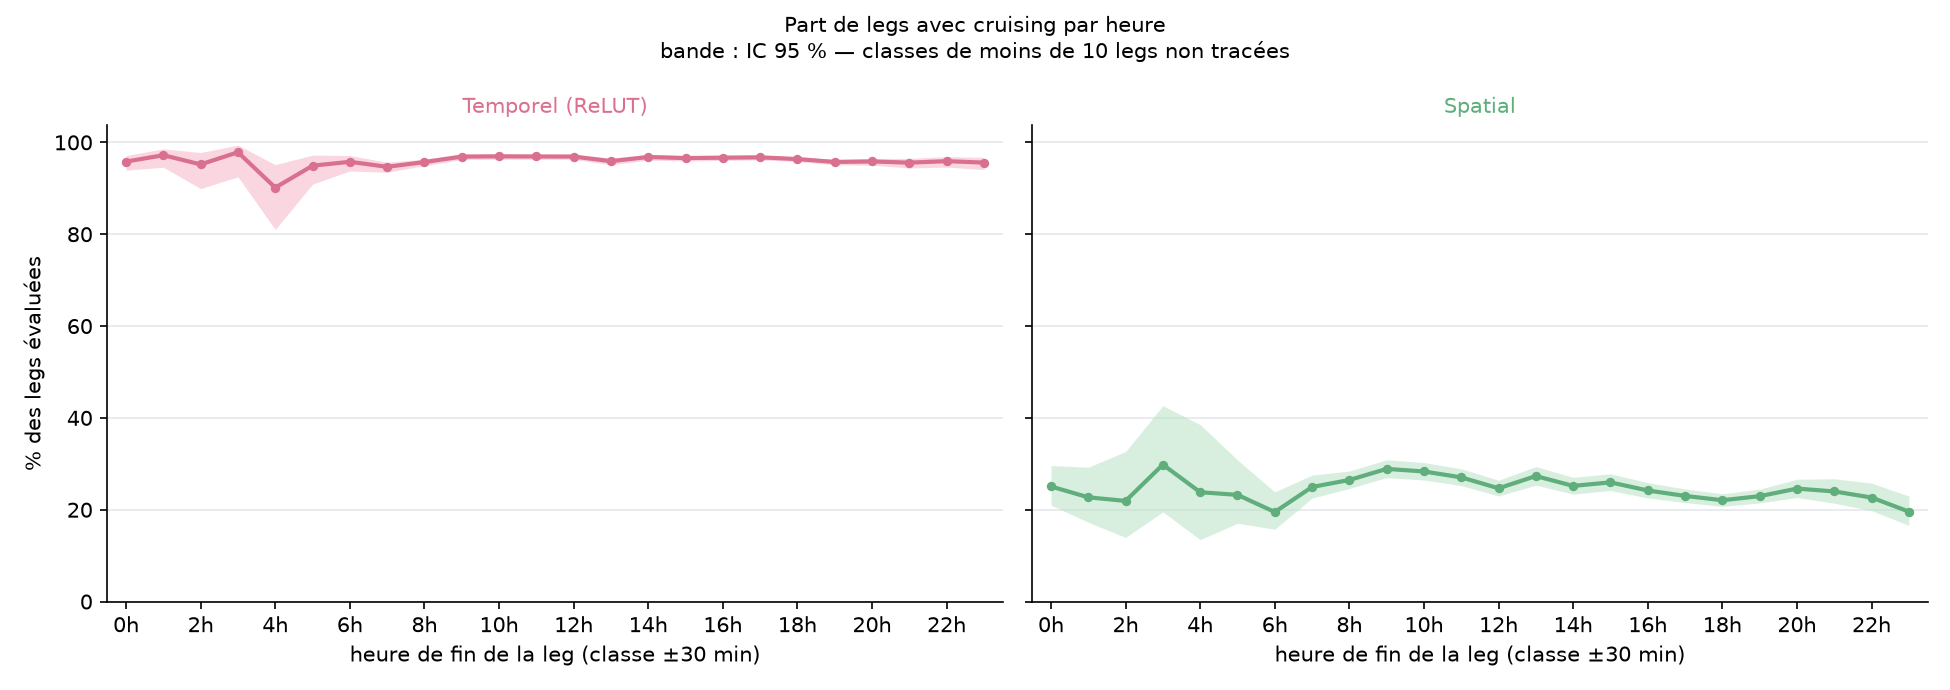

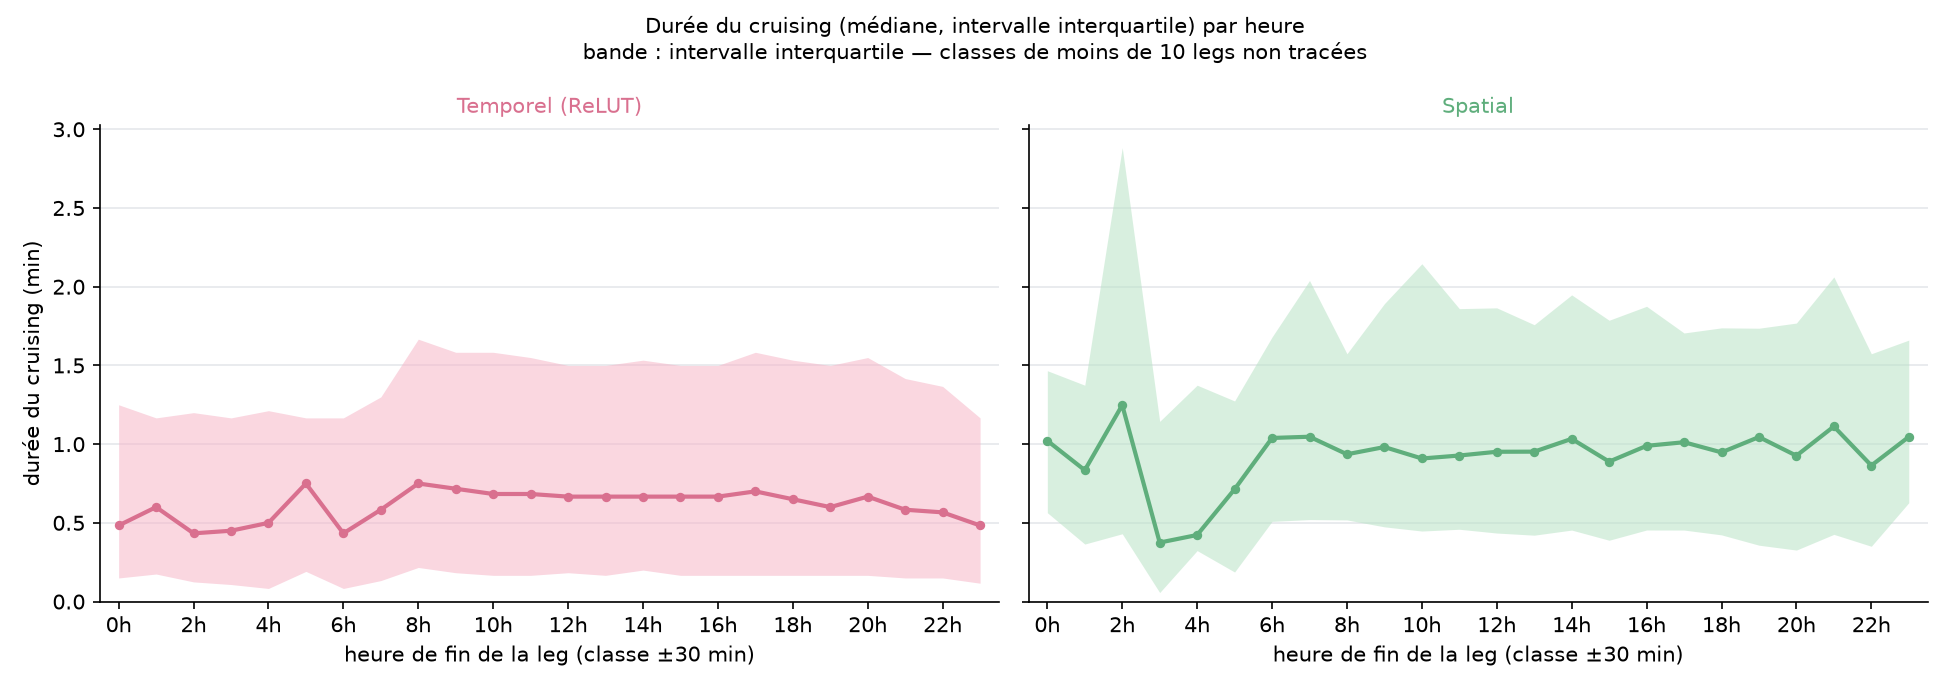

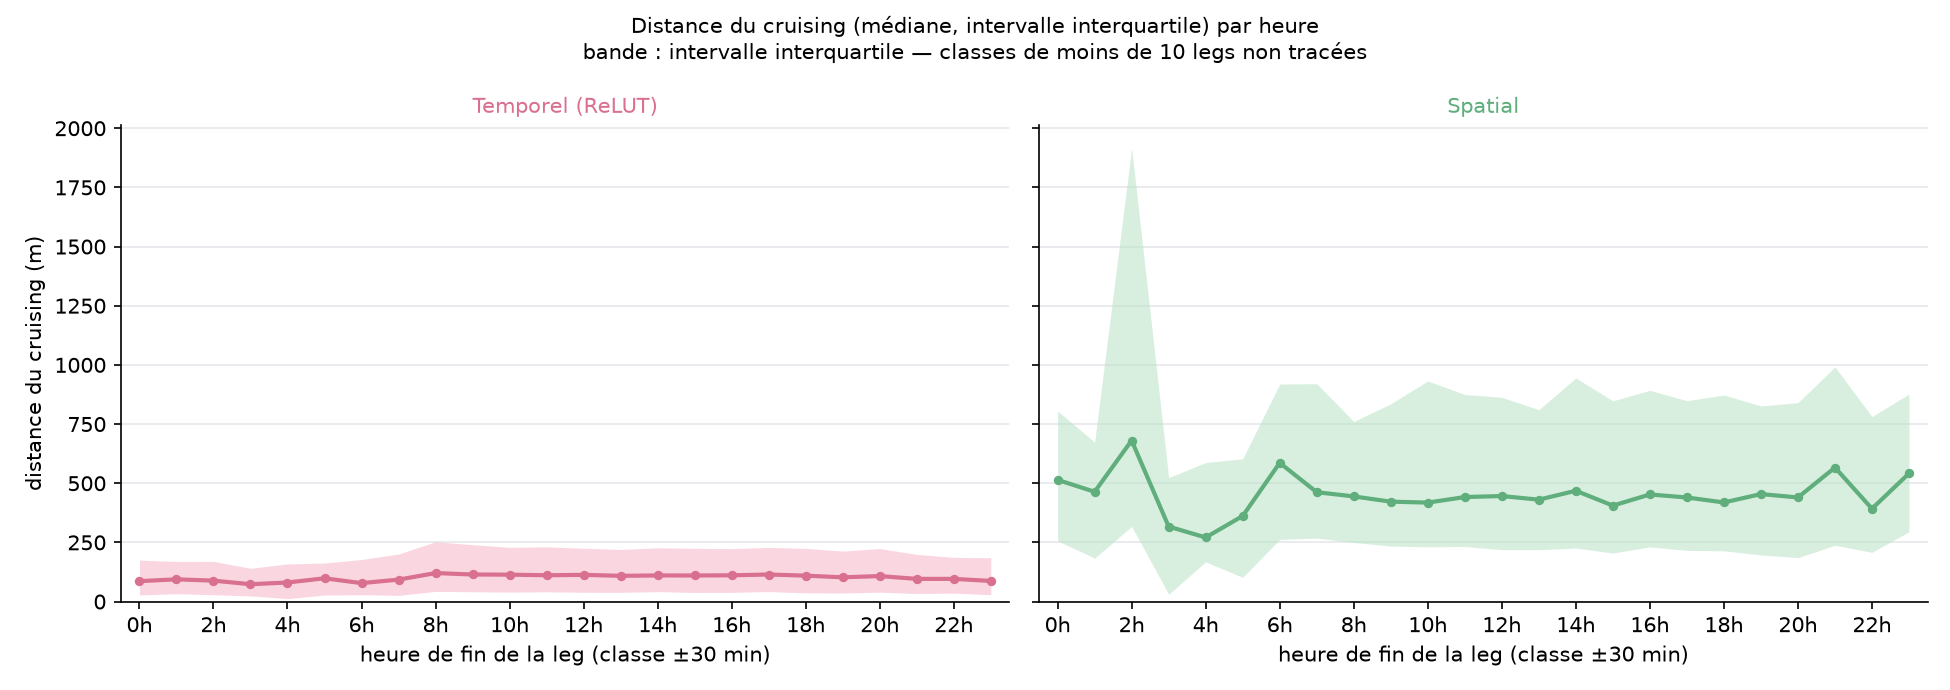

In [3]:
for indicator in ("share", "duration", "distance"):
    display(Image(filename=result["summary"]["figures"][f"{indicator}_hour"]))

In [4]:
columns = ["methode", "classe", "n_legs_evaluees", "n_legs_cruising", "part_cruising",
           "duree_min_moyenne", "duree_min_mediane", "distance_m_moyenne", "distance_m_mediane"]
result["tables"]["hour"][columns].round(3)

,methode,classe,n_legs_evaluees,n_legs_cruising,part_cruising,duree_min_moyenne,duree_min_mediane,distance_m_moyenne,distance_m_mediane
0,Temporel (ReLUT),0,621,595,0.958,1.070,0.483,248.574,86.266
1,Temporel (ReLUT),1,286,278,0.972,0.990,0.600,173.295,93.990
2,Temporel (ReLUT),2,125,119,0.952,0.990,0.433,186.637,88.437
3,Temporel (ReLUT),3,93,91,0.978,1.140,0.450,191.787,73.337
4,Temporel (ReLUT),4,71,64,0.901,1.407,0.500,634.956,80.552
5,Temporel (ReLUT),5,197,187,0.949,0.989,0.750,197.762,98.415
6,Temporel (ReLUT),6,567,543,0.958,1.002,0.433,212.491,78.000
7,Temporel (ReLUT),7,1653,1565,0.947,0.918,0.583,158.416,92.777
8,Temporel (ReLUT),8,3121,2987,0.957,1.368,0.750,283.286,120.479
9,Temporel (ReLUT),9,3130,3033,0.969,1.255,0.717,253.308,114.394


## Par motif du trip

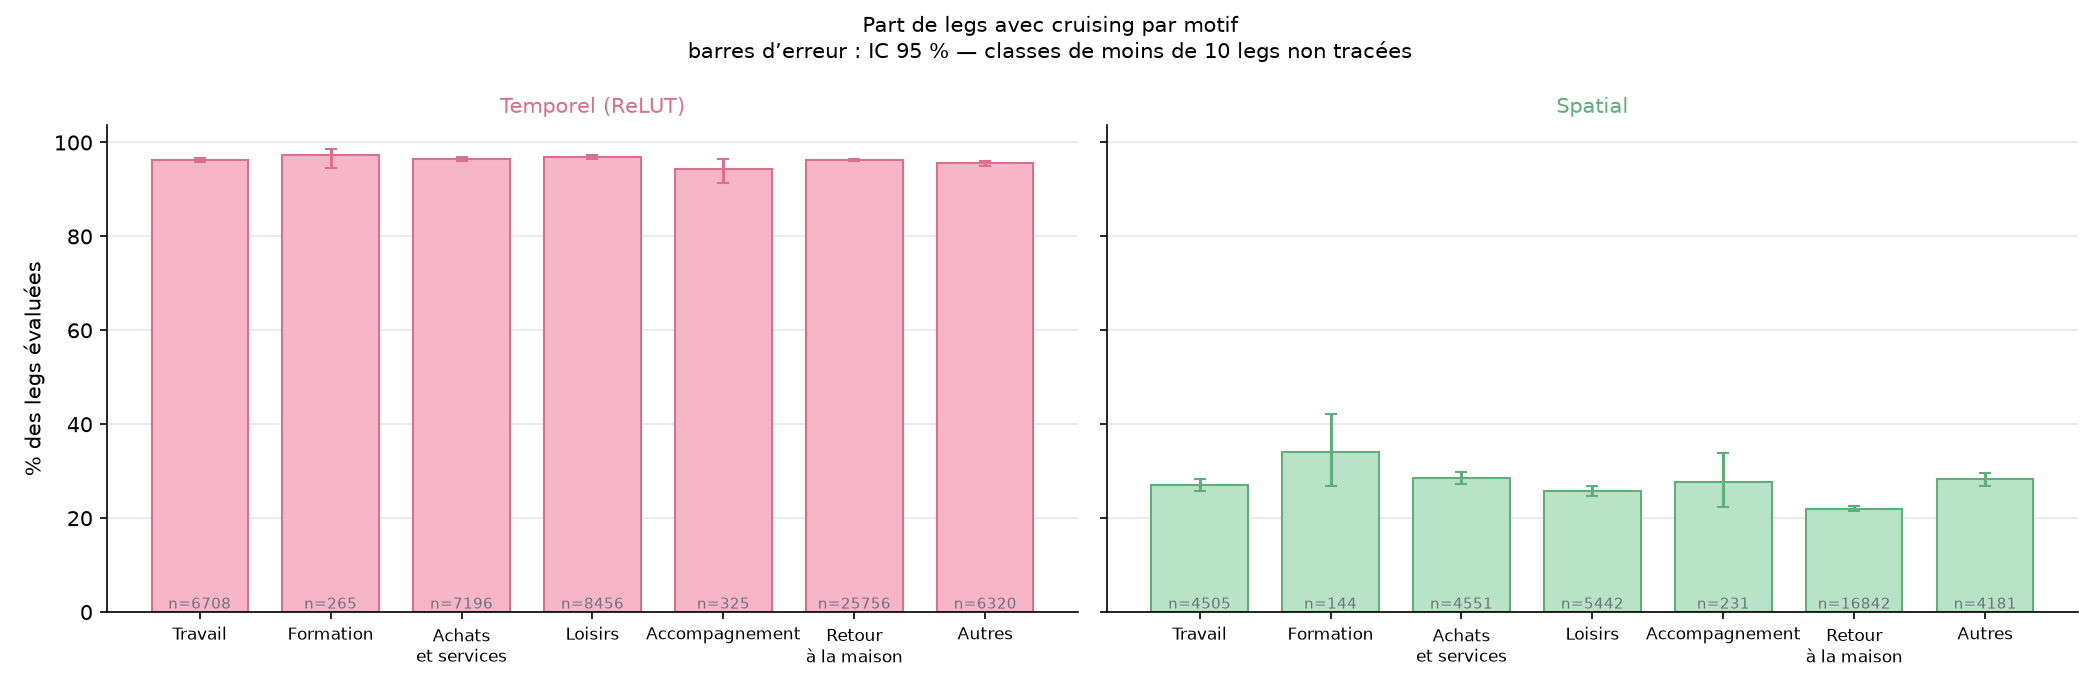

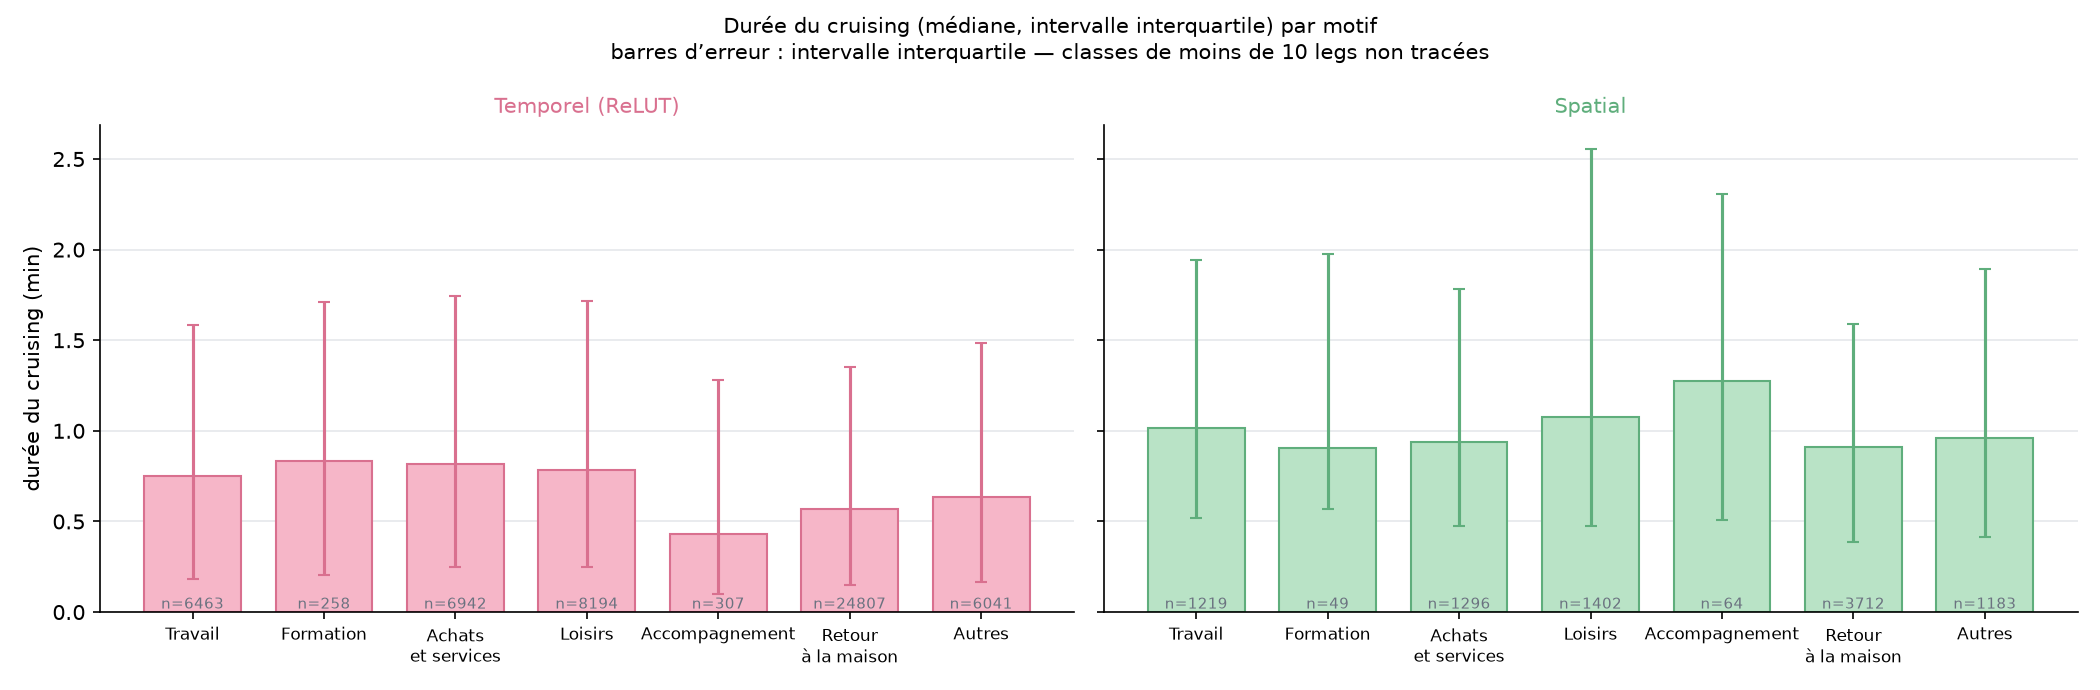

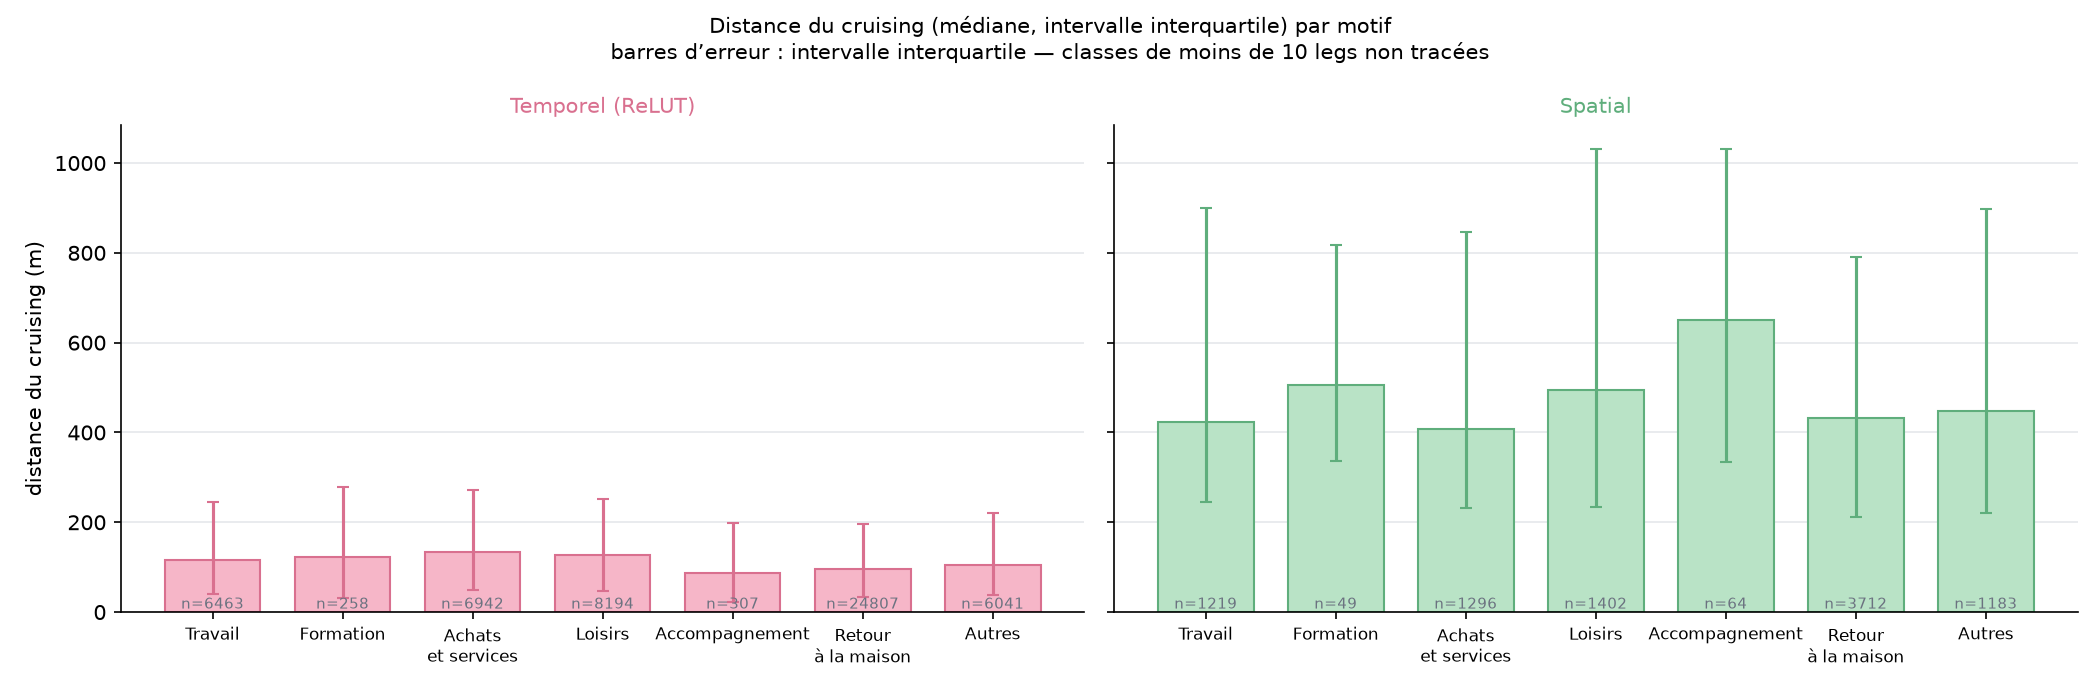

In [5]:
for indicator in ("share", "duration", "distance"):
    display(Image(filename=result["summary"]["figures"][f"{indicator}_purpose"]))

In [6]:
columns = ["methode", "classe", "n_legs_evaluees", "n_legs_cruising", "part_cruising",
           "duree_min_moyenne", "duree_min_mediane", "distance_m_moyenne", "distance_m_mediane"]
result["tables"]["purpose"][columns].round(3)

,methode,classe,n_legs_evaluees,n_legs_cruising,part_cruising,duree_min_moyenne,duree_min_mediane,distance_m_moyenne,distance_m_mediane
0,Temporel (ReLUT),Travail,6708,6463,0.963,1.228,0.750,237.963,114.925
1,Temporel (ReLUT),Formation,265,258,0.974,1.280,0.833,219.737,121.900
2,Temporel (ReLUT),Achats et services,7196,6942,0.965,1.321,0.817,238.142,134.880
3,Temporel (ReLUT),Loisirs,8456,8194,0.969,1.305,0.783,223.488,126.856
4,Temporel (ReLUT),Accompagnement,325,307,0.945,0.976,0.433,166.885,87.086
5,Temporel (ReLUT),Retour à la maison,25756,24807,0.963,1.143,0.567,235.113,96.220
6,Temporel (ReLUT),Autres,6320,6041,0.956,1.172,0.633,224.379,103.871
7,Spatial,Travail,4505,1219,0.271,1.862,1.018,720.919,423.394
8,Spatial,Formation,144,49,0.340,1.712,0.903,794.262,505.920
9,Spatial,Achats et services,4551,1296,0.285,1.788,0.937,682.941,407.515


## Répartition des legs avec cruising

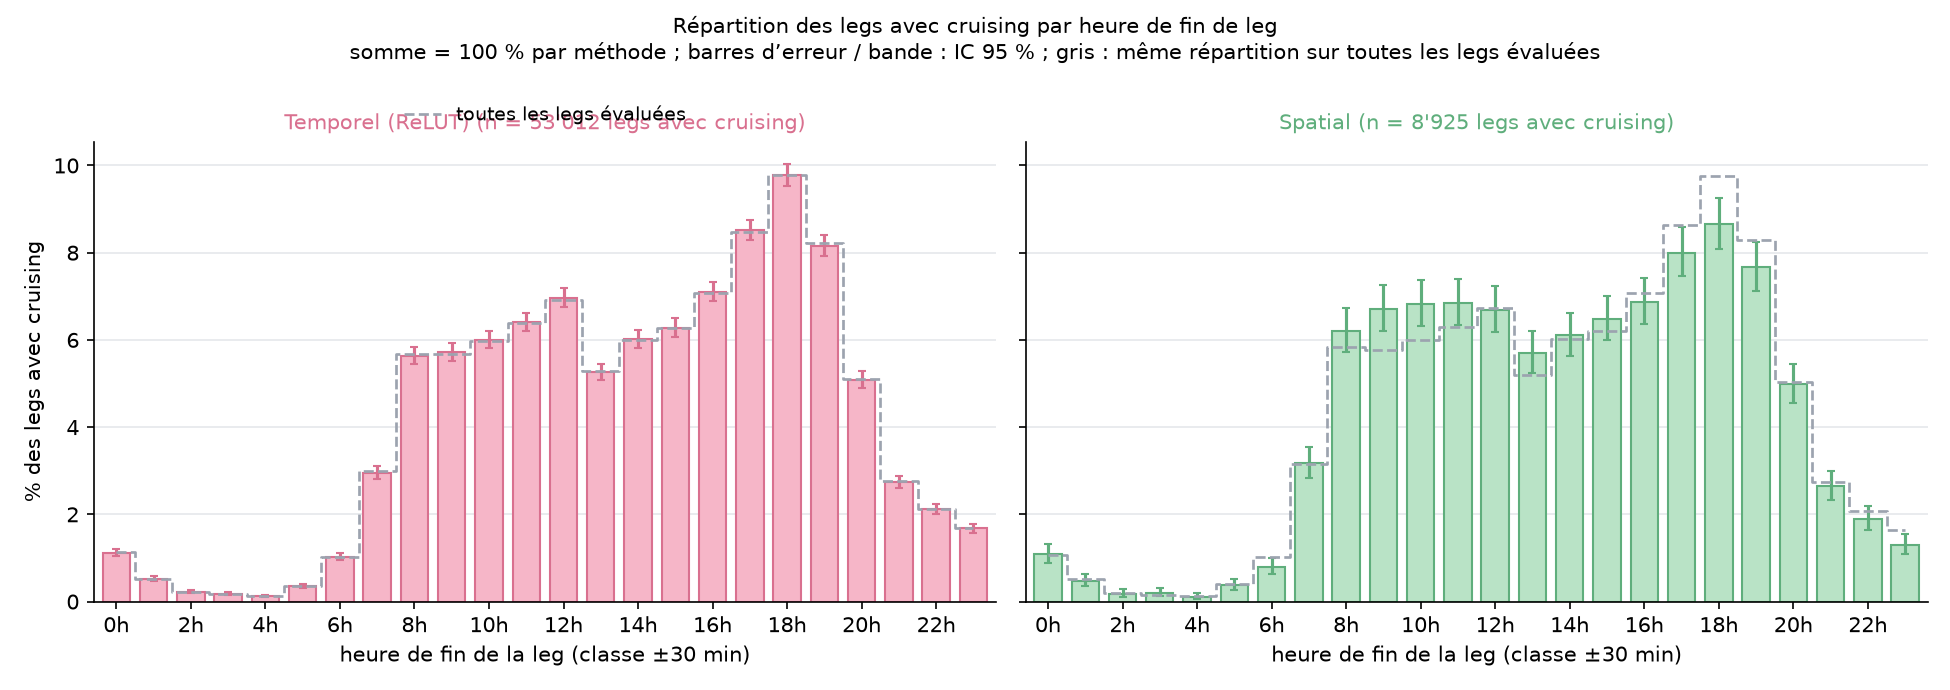

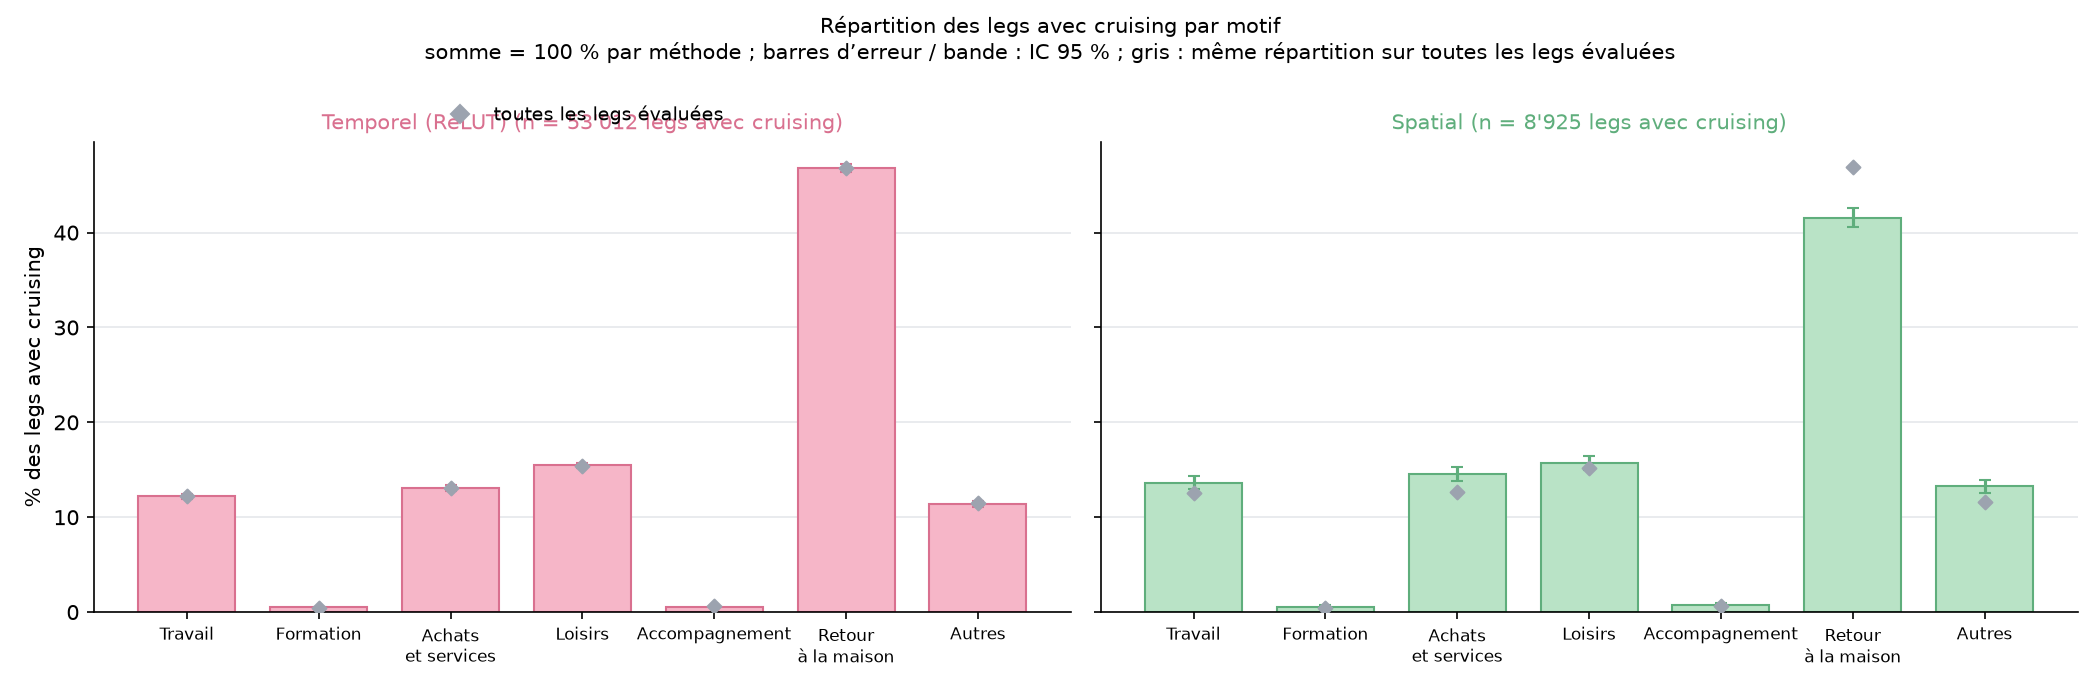

In [7]:
for dimension in ("hour", "purpose"):
    display(Image(filename=result["summary"]["figures"][f"composition_{dimension}"]))

In [8]:
columns = ["methode", "classe", "n_legs_cruising", "part_cruising", "part_ic95_bas", "part_ic95_haut", "part_reference"]
display(result["compositions"]["purpose"][columns].round(3))
result["compositions"]["hour"][columns].round(3)

,methode,classe,n_legs_cruising,part_cruising,part_ic95_bas,part_ic95_haut,part_reference
0,Temporel (ReLUT),Travail,6463,0.122,0.119,0.125,0.122
1,Temporel (ReLUT),Formation,258,0.005,0.004,0.005,0.005
2,Temporel (ReLUT),Achats et services,6942,0.131,0.128,0.134,0.131
3,Temporel (ReLUT),Loisirs,8194,0.155,0.152,0.158,0.154
4,Temporel (ReLUT),Accompagnement,307,0.006,0.005,0.006,0.006
5,Temporel (ReLUT),Retour à la maison,24807,0.468,0.464,0.472,0.468
6,Temporel (ReLUT),Autres,6041,0.114,0.111,0.117,0.115
7,Spatial,Travail,1219,0.137,0.130,0.144,0.126
8,Spatial,Formation,49,0.005,0.004,0.007,0.004
9,Spatial,Achats et services,1296,0.145,0.138,0.153,0.127


,methode,classe,n_legs_cruising,part_cruising,part_ic95_bas,part_ic95_haut,part_reference
0,Temporel (ReLUT),0,595,0.011,0.010,0.012,0.011
1,Temporel (ReLUT),1,278,0.005,0.005,0.006,0.005
2,Temporel (ReLUT),2,119,0.002,0.002,0.003,0.002
3,Temporel (ReLUT),3,91,0.002,0.001,0.002,0.002
4,Temporel (ReLUT),4,64,0.001,0.001,0.002,0.001
5,Temporel (ReLUT),5,187,0.004,0.003,0.004,0.004
6,Temporel (ReLUT),6,543,0.010,0.009,0.011,0.010
7,Temporel (ReLUT),7,1565,0.030,0.028,0.031,0.030
8,Temporel (ReLUT),8,2987,0.056,0.054,0.058,0.057
9,Temporel (ReLUT),9,3033,0.057,0.055,0.059,0.057


## Indicateurs par hexagone H3 et carte interactive

Méthode temporelle, à partir des points des prédictions ReLUT (`relut_predictions.parquet`) et des waypoints voiture de l'étape 01 :

| Indicateur | Définition |
|---|---|
| Temps de cruising cumulé | somme, sur les points en recherche de l'hexagone, du temps jusqu'au point suivant (plafonné à `max_point_interval_s`) |
| Distance de cruising cumulée | somme des distances jusqu'au point suivant, points en recherche |
| Legs avec cruising | legs distinctes ayant au moins un point en recherche dans l'hexagone |
| Part du temps voiture en cruising | temps de cruising / temps voiture total des segments prédits dans l'hexagone |
| Fins de legs | legs voiture dont le dernier waypoint (stationnement) est dans l'hexagone |
| Fins de legs / legs qui traversent | part des legs passant par l'hexagone qui s'y arrêtent |

On somme des **durées** et non des points : compter les points favoriserait les traces échantillonnées finement. Une valeur n'est publiée que si au moins `H3_MIN_PERSONS` personnes **et** `H3_MIN_LEGS` legs y contribuent. Les populations sont celles du dernier run de l'étape 32 (indicateurs 1–4) et des legs du périmètre de l'étape 01 (5–6).

La carte HTML a une couche par indicateur (cases à cocher en haut à droite) ; la légende de chaque couche s'affiche quand elle est cochée. L'offre de stationnement OTC est disponible en couches « Parkings publics (OTC) » et « Places publiques en parking ».

In [9]:
if RUN_H3:
    config.setdefault("h3_indicators", {}).update(
        {"resolution": H3_RESOLUTION, "min_persons": H3_MIN_PERSONS, "min_legs": H3_MIN_LEGS,
         "parking_supply_file": PARKING_SUPPLY_FILE}
    )
    h3_result = run_h3_indicators(config)
    from IPython.display import HTML
    display(pd.Series({k: v for k, v in h3_result["summary"].items() if k not in ("map", "table")}, name="H3"))
    display(HTML(f'<p><a href="{Path(h3_result["summary"]["map"]).as_uri()}" target="_blank">Ouvrir la carte H3</a></p>'))
    h3_columns = ["cruising_time_min", "cruising_distance_km", "n_legs_cruising", "cruising_time_share", "n_leg_ends", "leg_end_rate"]
    display(h3_result["table"][h3_columns].sort_values("cruising_time_min", ascending=False).head(10).round(3))

/Users/maximiliantrique/Documents/Projet_python/PARKING_SEARCH_PREDICTION/.venv/lib/python3.12/site-packages/pyogrio/raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiPoint' is converted to 'MultiPoint Z'
  return ogr_read(


resolution                                                                         8
min_persons                                                                        3
min_legs                                                                           3
max_point_interval_s                                                           120.0
predictions_scope                  toutes les legs, motifs Retour à la maison (pu...
hexagons_total                                                                 17767
hexagons_published_by_indicator    {'cruising_time_min': 708, 'cruising_distance_...
totals_before_masking              {'cruising_time_h': 481.59083333333336, 'cruis...
parking_supply                                             Data/GIS/OTC_PARKING.gpkg
Name: H3, dtype: object

,cruising_time_min,cruising_distance_km,n_legs_cruising,cruising_time_share,n_leg_ends,leg_end_rate
h3_cell,,,,,,
881f91ac65fffff,326.600,44.496,190.0,0.116,668.0,0.270
881f91a003fffff,313.300,69.525,155.0,0.184,293.0,0.197
881f913257fffff,304.650,68.545,214.0,0.131,418.0,0.235
881f91af33fffff,291.650,50.438,194.0,0.153,390.0,0.195
881f91a0d9fffff,257.267,51.890,215.0,0.152,461.0,0.258
881f91ad59fffff,235.450,40.946,172.0,0.140,493.0,0.280
881f91a625fffff,230.483,47.402,179.0,0.101,624.0,0.237
881f91a627fffff,228.683,48.034,192.0,0.150,724.0,0.388
881f91af59fffff,224.700,39.913,197.0,0.111,396.0,0.221


## Histogramme des durées ReLUT, filtré par stationnement déclaré et par motif

Choisis une ou plusieurs variables de stationnement du questionnaire (`space_home`, `space_work`) avec les catégories à garder, et/ou un ou plusieurs motifs. `HIST_GROUP_BY` superpose un histogramme par modalité (par exemple les trois catégories de `space_home`) ; la courbe grise en tirets est la référence : toutes les legs évaluées, sans filtre. La première cellule liste les modalités disponibles.

In [10]:
from parking_search_prediction.indicators import filter_legs, load_duration_table, plot_duration_histogram

duration_legs = load_duration_table(config, "relut", sample_run_id=SAMPLE_RUN_ID)
for column in ("space_home", "space_work", PURPOSE_COLUMN):
    if column in duration_legs:
        display(duration_legs[column].value_counts(dropna=False).rename(f"{column} (legs évaluées)"))

space_home
Place dédiée                                 46917
Aucun                                         3279
Pas de place dédiée, pas besoin de cruise     3039
Pas de place dédiée, besoin de cruise         1728
None                                            63
Name: space_home (legs évaluées), dtype: int64

space_work
None                                         35347
Pas de place dédiée, pas besoin de cruise    13030
Pas de place dédiée, besoin de cruise         4356
Place dédiée                                  2293
Name: space_work (legs évaluées), dtype: int64

purpose_agg
Retour à la maison    25756
Loisirs                8456
Achats et services     7196
Travail                6708
Autres                 6320
Accompagnement          325
Formation               265
Name: purpose_agg (legs évaluées), dtype: int64

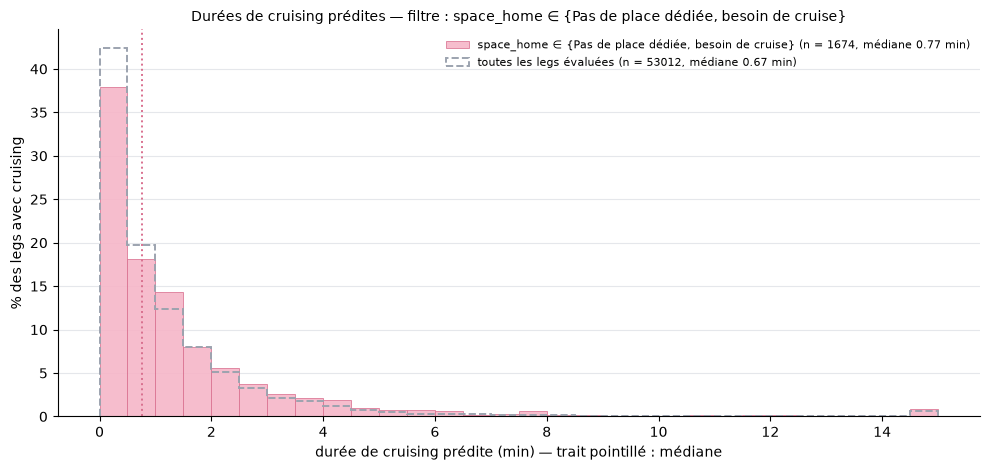

,groupe,n_legs,n_legs_histogramme,duree_moyenne_min,duree_mediane_min,duree_q25_min,duree_q75_min
0,"space_home ∈ {Pas de place dédiée, besoin de c...",1728,1674,1.44,0.77,0.25,1.75
1,référence : toutes les legs évaluées,55026,53012,1.20,0.67,0.17,1.50


In [11]:
# Catégories de stationnement à garder, par variable ({} = pas de filtre)
HIST_PARKING = {
    "space_home": ["Pas de place dédiée, besoin de cruise"],
    # "space_work": ["Pas de place dédiée, besoin de cruise"],
}
HIST_PARKING_MODE = "and"          # "and" : toutes les conditions ; "or" : au moins une
HIST_PURPOSES = None               # ex. ["Travail", "Retour à la maison"] ; None = tous les motifs
HIST_GROUP_BY = None               # None, "space_home", "space_work" ou PURPOSE_COLUMN : un histogramme par modalité
HIST_INCLUDE_NO_CRUISING = False   # True : inclut les legs sans cruising (durée 0)
HIST_MAX_MINUTES = 15              # borne de l'axe (le modèle plafonne à 15 min)
HIST_BIN_MINUTES = 0.5

selection, selection_label = filter_legs(
    duration_legs, parking=HIST_PARKING, parking_mode=HIST_PARKING_MODE,
    purposes=HIST_PURPOSES, purpose_column=PURPOSE_COLUMN,
)
fig, hist_stats = plot_duration_histogram(
    duration_legs, selection=selection, selection_label=selection_label, group_by=HIST_GROUP_BY,
    include_no_cruising=HIST_INCLUDE_NO_CRUISING, min_duration_s=MIN_CRUISING_DURATION_S,
    max_minutes=HIST_MAX_MINUTES, bin_minutes=HIST_BIN_MINUTES,
)
display(fig)
plt.close(fig)
hist_stats.round(2)